# Real-time log anomaly detection: EDA + Isolation Forest

**Goal:** detect anomalies in streaming log events using only the `severity` and `message` columns (as in `train.csv`, where the columns are `type` / `line`).

**Plan**
1. EDA on `train.csv` (is it usable for supervised learning?)
2. EDA on `test.csv` (what does the live stream look like?)
3. Message templating + feature engineering (streaming-safe, causal features)
4. Model comparison: Isolation Forest vs LOF vs One-Class SVM vs a severity rule
5. Ablations, hyper-parameters, seed stability
6. Time-split ("train on the past, score the future") evaluation
7. Streaming (micro-batch) simulation + saving the detector

> **Note on evaluation:** neither file has trustworthy ground truth (the `train.csv` labels turn out to be message-level and arbitrary, see Part 1; `test.csv` has no labels). For *evaluation only* I build **proxy labels** from columns the model never sees (`event_type`, `source_ip`, `bytes_out`). Treat the resulting numbers as a sanity check, not a production benchmark.

In [19]:
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, KFold, StratifiedGroupKFold, cross_val_predict
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 100)

SEED = 42
DATA_DIR = next(p for p in [Path("data"), Path.cwd(), Path(r"c:\Users\karin\Downloads")] if (p / "train.csv").exists())
ART_DIR = Path("artifacts")
ART_DIR.mkdir(exist_ok=True)
print("data dir:", DATA_DIR.resolve())

data dir: D:\anamoly_detection_ml\data


## Part 1 - EDA of `train.csv`

In [20]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["timestamp"])
print("train:", train.shape, "| test:", test.shape)
display(train.head(8))
print("nulls:", train.isna().sum().to_dict())
print("exact duplicate rows:", train.duplicated().sum(), "of", len(train))

train: (159, 3) | test: (10000, 12)


,type,line,anomaly_score
0,INFO,INFO Database connection failed,-1
1,ERROR,ERROR API request received: POST /order,-1
2,INFO,INFO Database connection failed,-1
3,ERROR,ERROR Query executed successfully,-1
4,ERROR,ERROR CPU usage at 95%,-1
5,ERROR,ERROR Failed login attempt detected,1
6,WARNING,WARNING CPU usage at 95%,-1
7,INFO,CRITICAL Database connection failed,-1


nulls: {'type': 0, 'line': 0, 'anomaly_score': 0}
exact duplicate rows: 119 of 159


`anomaly_score` uses the scikit-learn `predict()` convention (**-1 = anomaly, 1 = normal**), which hints the labels were produced by an Isolation-Forest-like model, not by a human.

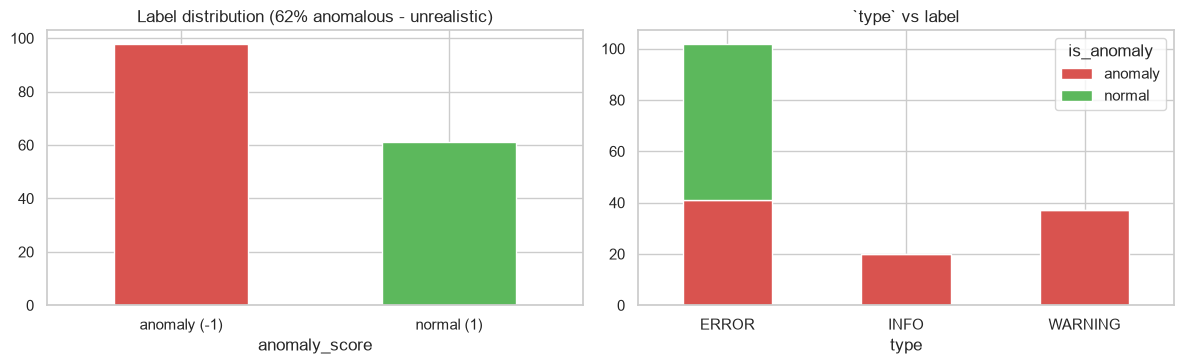

`type` != severity inside `line`: 2 rows


,type,line,anomaly_score,is_anomaly,sev,msg
7,INFO,CRITICAL Database connection failed,-1,1,CRITICAL,Database connection failed
76,INFO,CRITICAL Database connection failed,-1,1,CRITICAL,Database connection failed


In [21]:
train["is_anomaly"] = (train.anomaly_score == -1).astype(int)
train[["sev", "msg"]] = train.line.str.split(n=1, expand=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
train.anomaly_score.map({-1: "anomaly (-1)", 1: "normal (1)"}).value_counts().plot.bar(ax=ax[0], color=["#d9534f", "#5cb85c"], rot=0)
ax[0].set_title("Label distribution (62% anomalous - unrealistic)")
pd.crosstab(train.type, train.is_anomaly.map({1: "anomaly", 0: "normal"})).plot.bar(stacked=True, ax=ax[1], color=["#d9534f", "#5cb85c"], rot=0)
ax[1].set_title("`type` vs label")
plt.tight_layout(); plt.show()

print("`type` != severity inside `line`:", (train.type != train.sev).sum(), "rows")
display(train[train.type != train.sev])

Every INFO and WARNING row is "anomalous", and ERROR is split. So severity is **not** a clean signal. Let's check what the label actually depends on.

unique messages: 30 | lines with conflicting labels: 0


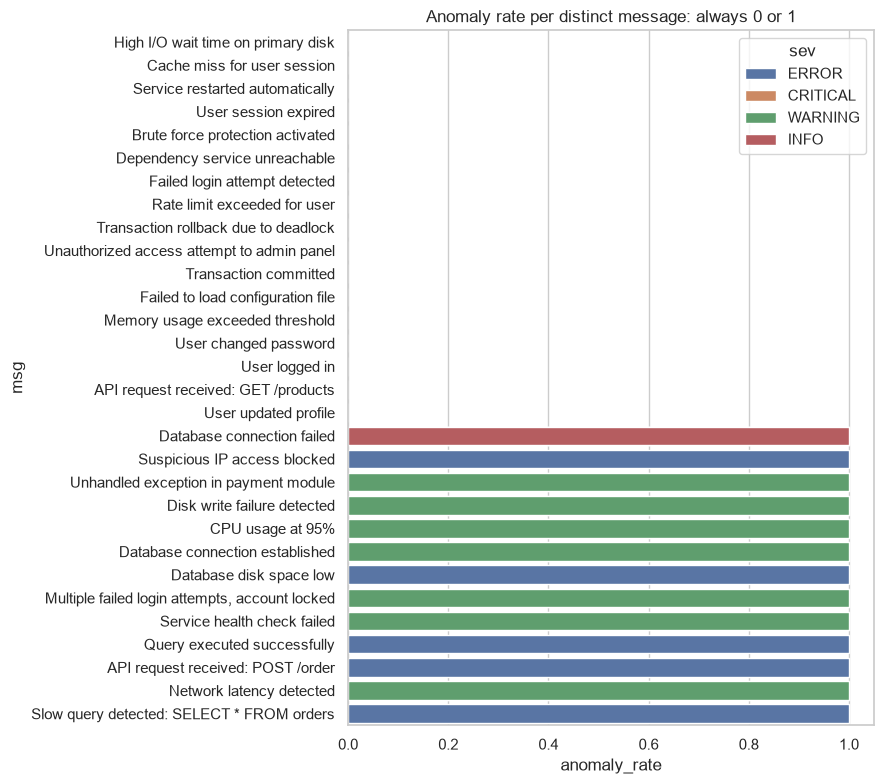

In [22]:
per_msg = (train.groupby(["msg", "sev"]).is_anomaly.agg(n="size", anomaly_rate="mean").reset_index()
           .sort_values(["anomaly_rate", "n"]))
print("unique messages:", train.msg.nunique(), "| lines with conflicting labels:",
      (train.groupby("line").anomaly_score.nunique() > 1).sum())

plt.figure(figsize=(9, 8))
sns.barplot(data=per_msg, y="msg", x="anomaly_rate", hue="sev", dodge=False)
plt.title("Anomaly rate per distinct message: always 0 or 1")
plt.tight_layout(); plt.show()

**Finding:** the label is a *deterministic function of the message string* (rate is exactly 0 or 1 for each of the 30 messages), and it is semantically arbitrary ("Failed login attempt detected" = normal, "Query executed successfully" = anomaly).

A supervised model could only memorise strings. Let's prove that: compare random K-fold (leaks duplicates) with **group K-fold by message** (unseen messages, like in the real stream).

In [23]:
y = train.is_anomaly
clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
pred_random = cross_val_predict(clf, train.line, y, cv=KFold(5, shuffle=True, random_state=0))
pred_group = cross_val_predict(clf, train.line, y, cv=GroupKFold(5), groups=train.msg)
sev_rule = (train.type != "ERROR").astype(int)

res = pd.DataFrame({
    "accuracy": {"majority class": max(y.mean(), 1 - y.mean()),
                 "rule: severity != ERROR": (sev_rule == y).mean(),
                 "LogReg, random KFold (leaky)": (pred_random == y).mean(),
                 "LogReg, GroupKFold by message": (pred_group == y).mean()},
    "F1(anomaly)": {"majority class": f1_score(y, np.ones(len(y))),
                    "rule: severity != ERROR": f1_score(y, sev_rule),
                    "LogReg, random KFold (leaky)": f1_score(y, pred_random),
                    "LogReg, GroupKFold by message": f1_score(y, pred_group)}})
display(res.round(3))

,accuracy,F1(anomaly)
majority class,0.616,0.763
rule: severity != ERROR,0.742,0.735
"LogReg, random KFold (leaky)",0.975,0.980
"LogReg, GroupKFold by message",0.799,0.835


Random K-fold looks great only because duplicates leak across folds; on unseen messages the model is no better than the trivial severity rule.

**Conclusion (train):** 159 rows / 30 distinct messages / arbitrary labels / unrealistic anomaly rate. `train.csv` is **not suitable for supervised training** or as ground truth. We use it for EDA only and go **unsupervised** on the stream.

## Part 2 - EDA of `test.csv` (the live stream)

In [24]:
print(test.shape); display(test.head(3))
print("nulls:", int(test.isna().sum().sum()), "| duplicate event_id:", test.event_id.duplicated().sum(),
      "| time-sorted:", test.timestamp.is_monotonic_increasing)
print("time range:", test.timestamp.min(), "->", test.timestamp.max())
display(test.describe(include="all").T[["count", "unique", "top", "freq"]].head(12))

(10000, 12)


,event_id,timestamp,host,source_ip,dest_ip,dest_port,username,event_type,severity,country,bytes_out,message
0,6bcf32d4-07fa-4601-bd43-a1ca4ef0f9f6,2026-10-16 02:37:00,vpn-01,45.11.185.108,10.0.30.6,443,root,login_success,ERROR,IN,0,root logged in from 45.11.185.108 outside business hours
1,205f459f-f70d-4f52-9510-0c2c71687702,2026-10-16 02:37:40,auth-01,45.11.185.108,10.0.30.5,22,root,privilege_escalation,CRITICAL,IN,0,sudo session opened for root
2,2580e8ef-b56a-445b-8f8d-65dfb7829417,2026-10-16 02:39:00,db-01,45.11.185.108,10.0.20.5,5432,root,file_access,ERROR,IN,0,Database dump of customers table


nulls: 0 | duplicate event_id: 0 | time-sorted: True
time range: 2026-10-16 02:37:00 -> 2026-10-16 14:28:26.679000


,count,unique,top,freq
event_id,10000,10000,6bcf32d4-07fa-4601-bd43-a1ca4ef0f9f6,1
timestamp,10000,NaN,NaN,NaN
host,10000,36,web-01,2090
source_ip,10000,47,10.0.1.26,342
dest_ip,10000,589,10.0.10.11,2090
dest_port,10000.0,NaN,NaN,NaN
username,10000,33,-,717
event_type,10000,11,web_request,3681
severity,10000,4,INFO,8637
country,10000,10,US,7642


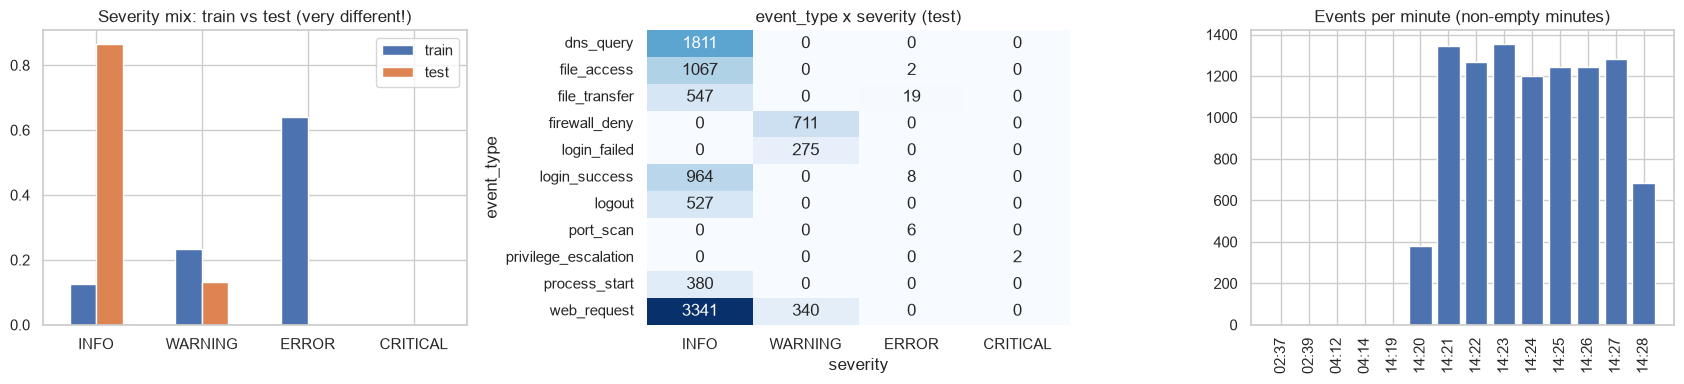

In [25]:
sev_order = ["INFO", "WARNING", "ERROR", "CRITICAL"]
cmp = pd.DataFrame({"train": train.type.value_counts(normalize=True), "test": test.severity.value_counts(normalize=True)}).reindex(sev_order).fillna(0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cmp.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Severity mix: train vs test (very different!)")
sns.heatmap(pd.crosstab(test.event_type, test.severity)[[c for c in sev_order if c in test.severity.unique()]],
            annot=True, fmt="d", cmap="Blues", ax=ax[1], cbar=False); ax[1].set_title("event_type x severity (test)")
per_min = test.timestamp.dt.floor("min").value_counts().sort_index()
ax[2].bar(per_min.index.strftime("%H:%M"), per_min.values); ax[2].tick_params(axis="x", rotation=90)
ax[2].set_title("Events per minute (non-empty minutes)")
plt.tight_layout(); plt.show()

* In test, 99.6% of events are INFO/WARNING, the reverse of train.
* The stream is a ~9 minute burst (~1,300 events/min) plus 6 isolated events at 02:37 and 04:12 (off-hours).
* WARNING is mostly benign noise (firewall DROPs, HTTP 4xx/5xx and failed internal logins), so **severity alone over-alerts and also misses WARNING-level brute force**.

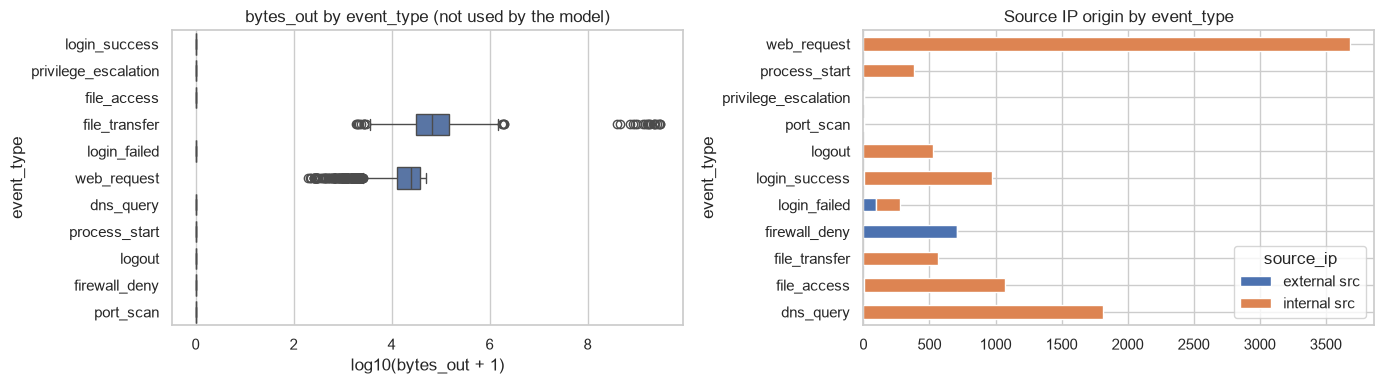

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=test, y="event_type", x=np.log10(test.bytes_out + 1), ax=ax[0]); ax[0].set_xlabel("log10(bytes_out + 1)")
ax[0].set_title("bytes_out by event_type (not used by the model)")
ext = ~test.source_ip.str.startswith("10.")
pd.crosstab(test.event_type, ext.map({True: "external src", False: "internal src"})).plot.barh(stacked=True, ax=ax[1])
ax[1].set_title("Source IP origin by event_type")
plt.tight_layout(); plt.show()

### Message templating
Raw messages have 2,000+ unique values only because of embedded usernames, IPs, ports, sizes. Masking those variable parts reveals the real vocabulary.

In [27]:
IP_RE = re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}\b")
USER_PREFIX_RE = re.compile(r"^(Accepted login for|Session closed for|Failed password for|sudo session opened for|VPN login for) (\S+)")


def to_template(msg: str) -> str:
    t = IP_RE.sub("<IP>", msg)
    t = USER_PREFIX_RE.sub(r"\1 <USER>", t)
    t = re.sub(r"^\w+ (logged in from)", r"<USER> \1", t)
    t = re.sub(r"\b(from|after) [A-Z]{2}\b", r"\1 <CC>", t)
    t = re.sub(r"files-\d+", "files-<N>", t)
    t = re.sub(r"doc\d+\.docx", "doc<N>.docx", t)
    t = re.sub(r"HTTP/\d\.\d", "HTTP/<V>", t)
    t = re.sub(r"\bport \d+", "port <PORT>", t)
    t = re.sub(r"(\bof )\d+( [MK]B)", r"\1<N>\2", t)
    t = re.sub(r"(<IP>):\d+$", r"\1:<PORT>", t)
    return t


test["tpl"] = test.message.map(to_template)
train_tpl = set(train.msg.map(to_template))
print(f"unique raw messages: {test.message.nunique()} -> unique templates: {test.tpl.nunique()}")
print("template overlap with train.csv:", len(set(test.tpl) & train_tpl), "(vocabularies are completely different)")
tpl_counts = test.groupby("tpl").agg(n=("tpl", "size"), severities=("severity", lambda s: ",".join(sorted(s.unique())))).sort_values("n")
display(tpl_counts.head(15))

unique raw messages: 2180 -> unique templates: 62
template overlap with train.csv: 0 (vocabularies are completely different)


,n,severities
tpl,,
sudo session opened for <USER>,2,CRITICAL
Database dump of customers table,2,ERROR
<USER> logged in from <IP> outside business hours,2,ERROR
VPN login for <USER> from <CC>,6,INFO
Port scan detected from <IP>,6,ERROR
VPN login for <USER> from <CC> two minutes after <CC>,6,ERROR
"""GET /dashboard HTTP/<V>"" 500",6,WARNING
"""GET /api/search HTTP/<V>"" 500",7,WARNING
"""GET /api/users HTTP/<V>"" 500",7,WARNING


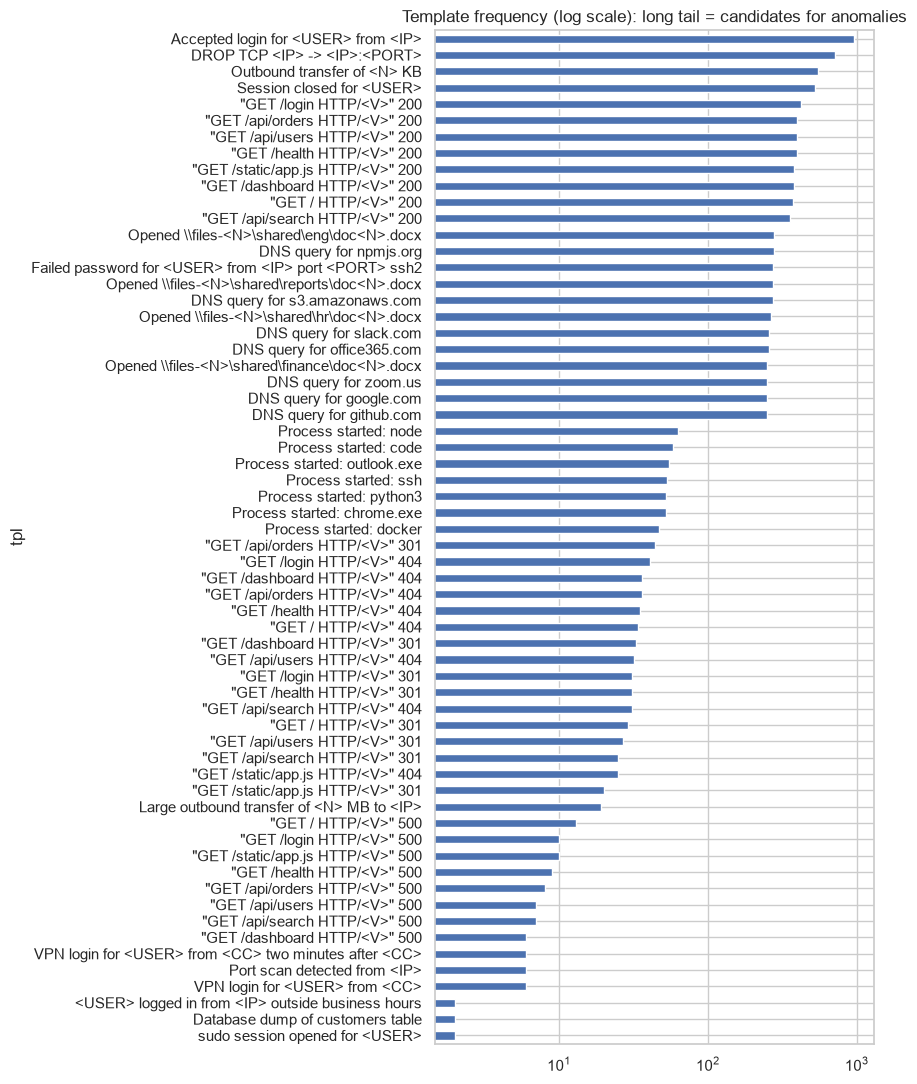

In [28]:
tpl_counts.n.plot.barh(figsize=(9, 11), logx=True, title="Template frequency (log scale): long tail = candidates for anomalies")
plt.tight_layout(); plt.show()

## Part 3 - Proxy ground truth (evaluation only)
Built from `event_type`, `source_ip`, `bytes_out`, none of which the model sees (the only overlap is that I use ERROR severity to tag the few suspicious logins / data dumps).

In [29]:
def label_attacks(df: pd.DataFrame) -> pd.Series:
    ext_src = ~df.source_ip.str.startswith("10.")
    lab = np.full(len(df), "normal", dtype=object)
    lab[((df.event_type == "file_transfer") & (df.bytes_out >= 100e6)).values] = "exfiltration"
    lab[(df.event_type == "port_scan").values] = "port_scan"
    lab[((df.event_type == "login_failed") & ext_src).values] = "ssh_brute_force"
    lab[((df.event_type == "login_success") & (df.severity == "ERROR")).values] = "suspicious_login"
    lab[(df.event_type == "privilege_escalation").values] = "privilege_escalation"
    lab[((df.event_type == "file_access") & (df.severity == "ERROR")).values] = "data_dump"
    return pd.Series(lab, index=df.index, name="attack")


test["attack"] = label_attacks(test)
test["y"] = (test.attack != "normal").astype(int)
print(f"proxy anomalies: {test.y.sum()} / {len(test)} = {test.y.mean():.2%}")
display(pd.crosstab(test.attack, test.severity))

proxy anomalies: 135 / 10000 = 1.35%


severity,CRITICAL,ERROR,INFO,WARNING
attack,,,,
data_dump,0,2,0,0
exfiltration,0,19,0,0
normal,0,0,8637,1228
port_scan,0,6,0,0
privilege_escalation,2,0,0,0
ssh_brute_force,0,0,0,98
suspicious_login,0,8,0,0


Notice `ssh_brute_force` (98 events) is **WARNING** severity, so a severity rule can never find it, and exfiltration/port scans are separated by rarity and bursts rather than severity alone.

## Part 4 - Feature engineering (streaming-safe)

Only `severity`, `message` and `timestamp` (used **only for ordering / windows**) are used.

| feature | meaning |
|---|---|
| `sev_ord` | INFO=0, WARNING=1, ERROR=2, CRITICAL=3 |
| `rarity` | `-log(freq of template in the reference window)`; unseen template = max rarity |
| `log_size_mb` | magnitude parsed from the message ("Large outbound transfer of 1477 MB") |
| `n_ext_ip` | number of non-private IPs mentioned in the message |
| `log_win10`, `log_win60` | **causal** count of events with the same (template, entity) in the last 10 / 60 s (raw burst volume) |
| `share10`, `share60` | **entity concentration**: of the same-template events in the last 10 / 60 s, the fraction coming from the *same entity* (IP / user in the message). ~0 for normal traffic spread over many entities, ~1 when one source dominates (brute force, scans, exfiltration) |
| `text_svd_*` | SVD of char-n-gram TF-IDF of the template (similarity of unseen templates) |

In [30]:
def parse_message(msg: str):
    ips = IP_RE.findall(msg)
    size = re.search(r"of (\d+) ([MK])B", msg)
    size_mb = int(size.group(1)) * (1.0 if size.group(2) == "M" else 1 / 1024) if size else 0.0
    n_ext = sum(not ip.startswith(("10.", "192.168.")) for ip in ips)
    user = USER_PREFIX_RE.match(msg)
    entity = ips[0] if ips else (user.group(2) if user else "")
    return size_mb, n_ext, entity


def window_counts(ts_sec: np.ndarray, keys: pd.Series, window: float) -> np.ndarray:
    """Causal count of events with the same key in (t - window, t], including the event itself. Input must be time-sorted."""
    out = np.zeros(len(ts_sec))
    for idx in keys.groupby(keys.values).indices.values():
        t = ts_sec[idx]
        out[idx] = np.arange(1, len(t) + 1) - np.searchsorted(t, t - window, side="left")
    return out


SEV_MAP = {"INFO": 0, "WARNING": 1, "ERROR": 2, "CRITICAL": 3}


class FeatureBuilder:
    def __init__(self, windows=(10, 60), svd_components=6, seed=SEED):
        self.windows, self.svd_components, self.seed = windows, svd_components, seed

    def fit(self, df):
        tpl = df.message.map(to_template)
        self.tpl_counts_ = tpl.value_counts().to_dict()
        self.n_ref_ = len(df)
        uniq = pd.Series(tpl.unique())
        self.tfidf_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit(uniq)
        self.svd_ = TruncatedSVD(self.svd_components, random_state=self.seed).fit(self.tfidf_.transform(uniq))
        return self

    def transform(self, df):
        """`df` must be sorted by timestamp and contain severity, message, timestamp."""
        tpl = df.message.map(to_template)
        parsed = pd.DataFrame(df.message.map(parse_message).tolist(), columns=["size_mb", "n_ext_ip", "entity"], index=df.index)
        ts = (df.timestamp - pd.Timestamp("1970-01-01")).dt.total_seconds().values
        tpl_s = tpl.reset_index(drop=True)
        key_s = (tpl + "|" + parsed.entity).reset_index(drop=True)
        has_entity = (parsed.entity.values != "")
        F = pd.DataFrame(index=df.index)
        F["sev_ord"] = df.severity.map(SEV_MAP).fillna(0).values
        cnt = tpl.map(self.tpl_counts_).fillna(0).values
        F["rarity"] = -np.log((cnt + 1) / (self.n_ref_ + 1))
        F["log_size_mb"] = np.log1p(parsed.size_mb.values)
        F["n_ext_ip"] = parsed.n_ext_ip.values
        for w in self.windows:
            k, t = window_counts(ts, key_s, w), window_counts(ts, tpl_s, w)
            F[f"log_win{w}"] = np.log1p(k)
            F[f"share{w}"] = np.where(has_entity, k / t, 0.0)
        svd = self.svd_.transform(self.tfidf_.transform(tpl))
        for i in range(svd.shape[1]):
            F[f"text_svd_{i}"] = svd[:, i]
        return F


B = ["sev_ord", "rarity", "log_size_mb", "n_ext_ip"]
SHARE, WIN, SVD = ["share10", "share60"], ["log_win10", "log_win60"], [f"text_svd_{i}" for i in range(6)]
FEATURE_SETS = {
    "A: severity + message rarity (what you specified)": ["sev_ord", "rarity"],
    "B: + message magnitude / external IP": B,
    "C: B + raw burst counts": B + WIN,
    "D: B + entity share (recommended)": B + SHARE,
    "E: D + raw burst counts": B + SHARE + WIN,
    "F: D + text SVD": B + SHARE + SVD,
}
FINAL_SET = "D: B + entity share (recommended)"

fb_full = FeatureBuilder().fit(test)
F_full = fb_full.transform(test)
display(F_full.join(test.attack).groupby("attack").mean().round(2))

,sev_ord,rarity,log_size_mb,n_ext_ip,log_win10,share10,log_win60,share60,text_svd_0,text_svd_1,text_svd_2,text_svd_3,text_svd_4,text_svd_5
attack,,,,,,,,,,,,,,
data_dump,2.00,8.11,0.00,0.00,0.69,0.00,0.69,0.00,0.04,0.09,0.04,-0.01,0.05,-0.01
exfiltration,2.00,6.21,7.30,1.00,0.97,1.00,1.20,0.82,0.02,0.13,0.16,0.09,-0.03,0.12
normal,0.12,3.43,0.01,0.07,1.96,0.09,3.15,0.06,0.26,0.14,0.18,0.06,-0.01,-0.02
port_scan,2.00,7.26,0.00,1.00,0.69,1.00,0.69,0.83,0.03,0.23,0.21,0.01,-0.05,0.21
privilege_escalation,3.00,8.11,0.00,0.00,0.69,1.00,0.69,1.00,0.04,0.27,0.35,0.18,0.03,0.17
ssh_brute_force,1.00,3.59,0.00,1.00,2.89,0.91,3.05,0.79,0.04,0.27,0.34,0.03,-0.04,0.25
suspicious_login,2.00,7.48,0.00,0.25,0.69,1.00,0.69,0.85,0.06,0.24,0.39,-0.03,-0.10,0.37


Attack classes already stand out on rarity / size / burst features (compare with the `normal` row).

## Part 5 - Model comparison
Metrics (higher is better): ROC-AUC, Average Precision (PR-AUC), and precision / recall / F1 for the **top-k alerts where k = 1.5% of the stream** (a realistic alert budget; true rate is 1.35%).

In [31]:
ALERT_BUDGET = 0.015


def evaluate(score, y, budget=ALERT_BUDGET):
    k = int(round(budget * len(y)))
    top = np.zeros(len(y), dtype=int); top[np.argsort(-score)[:k]] = 1
    return {"ROC_AUC": roc_auc_score(y, score), "AP": average_precision_score(y, score),
            "precision@k": precision_score(y, top), "recall@k": recall_score(y, top), "F1@k": f1_score(y, top)}


def if_scores(X, seed=SEED, **kw):
    params = dict(n_estimators=300, max_samples=256, contamination="auto", random_state=seed, n_jobs=-1) | kw
    return -IsolationForest(**params).fit(X).score_samples(X)


def lof_scores(X):
    lof = LocalOutlierFactor(n_neighbors=50, n_jobs=-1).fit(StandardScaler().fit_transform(X))
    return np.nan_to_num(-lof.negative_outlier_factor_, nan=-1.0, posinf=1e6)


def ocsvm_scores(X):
    Xs = StandardScaler().fit_transform(X)
    return -OneClassSVM(nu=0.02, gamma="scale").fit(Xs).decision_function(Xs)


y_true = test.y.values
rows = {}
for name, cols in FEATURE_SETS.items():
    X = F_full[cols].values
    rows[("IsolationForest", name)] = evaluate(if_scores(X), y_true)
cols_c = FEATURE_SETS[FINAL_SET]
rows[("LOF", FINAL_SET)] = evaluate(lof_scores(F_full[cols_c].values), y_true)
rows[("OneClassSVM", FINAL_SET)] = evaluate(ocsvm_scores(F_full[cols_c].values), y_true)
rows[("Rule: severity >= ERROR", "-")] = evaluate(F_full.sev_ord.values + np.random.default_rng(0).uniform(0, 1e-6, len(F_full)), y_true)

results = pd.DataFrame(rows).T.round(3)
results.index.names = ["model", "feature set"]
display(results.sort_values("AP", ascending=False))

ROC_AUC     AP  precision@k  recall@k   F1@k
model                   feature set                                                                                    
IsolationForest         F: D + text SVD                                      0.999  0.948        0.887     0.985  0.933
                        D: B + entity share (recommended)                    0.999  0.916        0.880     0.978  0.926
                        E: D + raw burst counts                              0.997  0.785        0.667     0.741  0.702
                        B: + message magnitude / external IP                 0.994  0.720        0.500     0.556  0.526
                        C: B + raw burst counts                              0.992  0.616        0.407     0.452  0.428
Rule: severity >= ERROR -                                                    0.954  0.393        0.293     0.326  0.309
IsolationForest         A: severity + message rarity (what you specified)    0.954  0.389        0.247     0.274  0.260
OneClassSVM             D: B + entity share (recommended)                    0.944  0.321        0.293     0.326  0.309
LOF                     D: B + entity share (recommended)                    0.762  0.278        0.180     0.200  0.189

**Reading the table:** a rule on severity can only reach what ERROR/CRITICAL covers (and never sees WARNING-level SSH brute force).

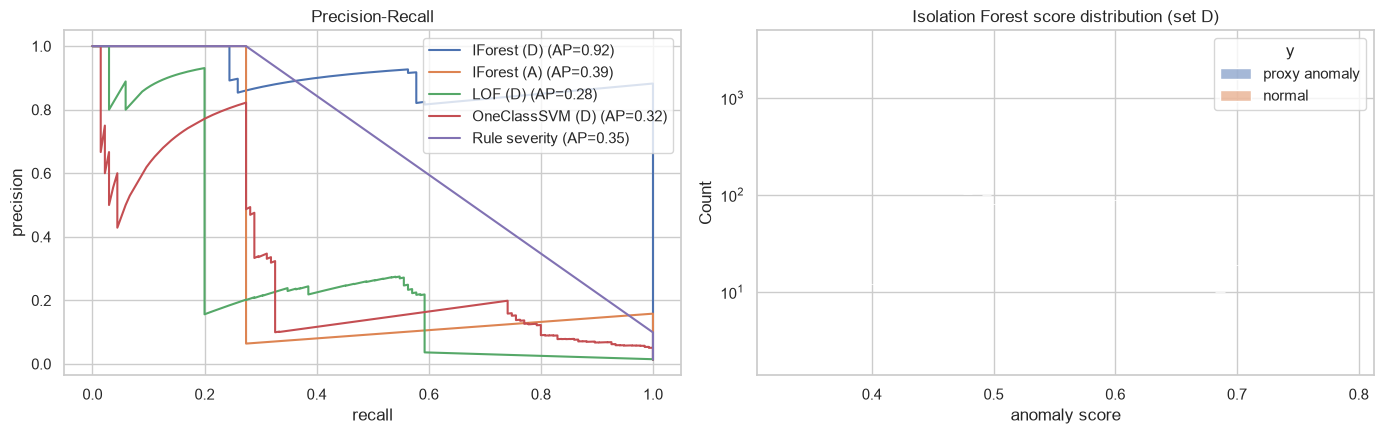

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
curves = {"IForest (D)": if_scores(F_full[cols_c].values), "IForest (A)": if_scores(F_full[FEATURE_SETS[list(FEATURE_SETS)[0]]].values),
          "LOF (D)": lof_scores(F_full[cols_c].values), "OneClassSVM (D)": ocsvm_scores(F_full[cols_c].values),
          "Rule severity": F_full.sev_ord.values.astype(float)}
for name, s in curves.items():
    p, r, _ = precision_recall_curve(y_true, s); ax[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_true, s):.2f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-Recall"); ax[0].legend()
s = curves["IForest (D)"]
sns.histplot(x=s, hue=test.y.map({0: "normal", 1: "proxy anomaly"}), bins=60, log_scale=(False, True), ax=ax[1])
ax[1].set_title("Isolation Forest score distribution (set D)"); ax[1].set_xlabel("anomaly score")
plt.tight_layout(); plt.show()

### Hyper-parameters and seed stability
Small grid on feature set D. (Tuned against proxy labels, so read as relative sensitivity, not an unbiased estimate.)

In [33]:
X_c = F_full[cols_c].values
grid = []
for ms in [64, 256, 1024, "auto"]:
    for ne in [100, 300]:
        for mf in [0.5, 1.0]:
            grid.append({"max_samples": ms, "n_estimators": ne, "max_features": mf} | evaluate(if_scores(X_c, max_samples=ms, n_estimators=ne, max_features=mf), y_true))
grid = pd.DataFrame(grid).round(3).sort_values("AP", ascending=False)
display(grid.head(8))

seeds = [evaluate(if_scores(X_c, seed=s), y_true) for s in range(10)]
print("seed stability (10 seeds, default params):")
display(pd.DataFrame(seeds).agg(["mean", "std"]).round(3))

,max_samples,n_estimators,max_features,ROC_AUC,AP,precision@k,recall@k,F1@k
1,64,100,1.0,0.999,0.950,0.887,0.985,0.933
3,64,300,1.0,0.998,0.938,0.867,0.963,0.912
0,64,100,0.5,0.996,0.928,0.813,0.904,0.856
7,256,300,1.0,0.999,0.916,0.880,0.978,0.926
15,auto,300,1.0,0.999,0.916,0.880,0.978,0.926
2,64,300,0.5,0.994,0.905,0.787,0.874,0.828
4,256,100,0.5,0.998,0.904,0.853,0.948,0.898
12,auto,100,0.5,0.998,0.904,0.853,0.948,0.898


seed stability (10 seeds, default params):


,ROC_AUC,AP,precision@k,recall@k,F1@k
mean,0.999,0.932,0.884,0.982,0.931
std,0.000,0.017,0.017,0.019,0.018


## Part 6 - "Train on the past, score the future"
The detector is fitted on the **first half of the stream only** (templates, TF-IDF/SVD, Isolation Forest, alert threshold). The second half is then scored with unchanged parameters, with window features computed causally over the full history, exactly as in production.

fit on rows [0, 5000), scored rows [5000, 10000) -> 53 proxy anomalies in the future half
{'ROC_AUC': 1.0, 'AP': 0.967, 'precision@k': 0.707, 'recall@k': 1.0, 'F1@k': 0.828}

At the fixed threshold learned on the past (alert rate 1.12%):
precision=0.946  recall=1.000  F1=0.972


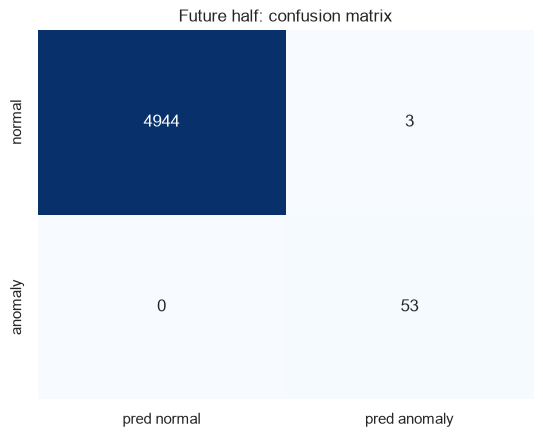

In [34]:
class AnomalyDetector:
    def __init__(self, columns, if_params=None, budget=ALERT_BUDGET):
        self.columns, self.budget = columns, budget
        self.if_params = dict(n_estimators=300, max_samples=256, contamination="auto", random_state=SEED, n_jobs=-1) | (if_params or {})

    def fit(self, df_ref):
        self.fb = FeatureBuilder().fit(df_ref)
        X = self.fb.transform(df_ref)[self.columns]
        self.model = IsolationForest(**self.if_params).fit(X.values)
        self.threshold = np.quantile(-self.model.score_samples(X.values), 1 - self.budget)
        return self

    def score_features(self, F):
        return -self.model.score_samples(F[self.columns].values)

    def score(self, df):
        return self.score_features(self.fb.transform(df))

    def predict(self, df):
        return (self.score(df) >= self.threshold).astype(int)


half = len(test) // 2
det_half = AnomalyDetector(cols_c).fit(test.iloc[:half])
s_all = det_half.score(test)
s_future, y_future = s_all[half:], y_true[half:]
pred_future = (s_future >= det_half.threshold).astype(int)

print(f"fit on rows [0, {half}), scored rows [{half}, {len(test)}) -> {y_future.sum()} proxy anomalies in the future half")
print({k: round(v, 3) for k, v in evaluate(s_future, y_future).items()})
print(f"\nAt the fixed threshold learned on the past (alert rate {pred_future.mean():.2%}):")
print(f"precision={precision_score(y_future, pred_future):.3f}  recall={recall_score(y_future, pred_future):.3f}  F1={f1_score(y_future, pred_future):.3f}")
sns.heatmap(confusion_matrix(y_future, pred_future), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["pred normal", "pred anomaly"], yticklabels=["normal", "anomaly"])
plt.title("Future half: confusion matrix"); plt.show()

### Final model: fit on the whole stream, inspect alerts
(Isolation Forest tolerates the ~1% contamination in the fit data. In production, refit periodically on a trailing window of recent traffic.)

In [35]:
det = AnomalyDetector(cols_c).fit(test)
test["score"] = det.score(test)
test["alert"] = (test.score >= det.threshold).astype(int)
print(f"threshold={det.threshold:.4f}  alerts={test.alert.sum()}  ({test.alert.mean():.2%})")
print("overall:", {k: round(v, 3) for k, v in evaluate(test.score.values, y_true).items()})

per_attack = test[test.y == 1].groupby("attack").agg(events=("alert", "size"), detected=("alert", "sum"))
per_attack["recall"] = (per_attack.detected / per_attack.events).round(3)
display(per_attack)

fp = test[(test.alert == 1) & (test.y == 0)]
print(f"false positives: {len(fp)}")
display(fp.groupby(["tpl", "severity"]).size().sort_values(ascending=False).head(10).to_frame("n"))

threshold=0.6872  alerts=153  (1.53%)
overall: {'ROC_AUC': 0.999, 'AP': 0.916, 'precision@k': 0.88, 'recall@k': 0.978, 'F1@k': 0.926}


,events,detected,recall
attack,,,
data_dump,2,2,1.0
exfiltration,19,19,1.0
port_scan,6,6,1.0
privilege_escalation,2,2,1.0
ssh_brute_force,98,98,1.0
suspicious_login,8,8,1.0


false positives: 18


,,n
tpl,severity,
DROP TCP <IP> -> <IP>:<PORT>,WARNING,9
VPN login for <USER> from <CC>,INFO,6
Failed password for <USER> from <IP> port <PORT> ssh2,WARNING,2
Session closed for <USER>,INFO,1


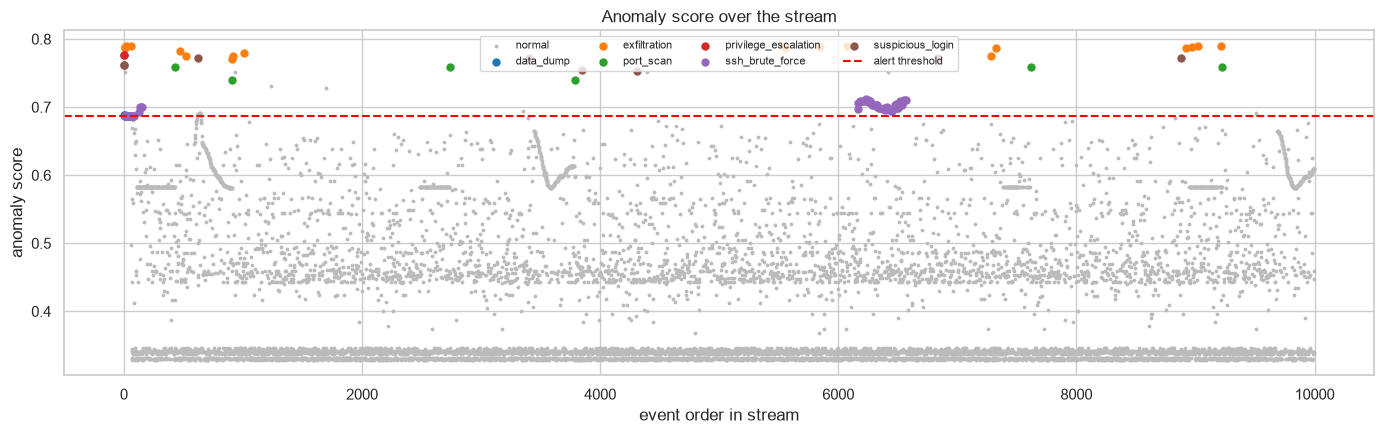

In [36]:
fig, ax = plt.subplots(figsize=(14, 4.5))
idx = np.arange(len(test))
ax.scatter(idx[test.y == 0], test.score[test.y == 0], s=3, c="#bbbbbb", label="normal")
for a, c in zip(per_attack.index, sns.color_palette("tab10", len(per_attack))):
    m = test.attack == a
    ax.scatter(idx[m], test.score[m], s=25, color=c, label=a)
ax.axhline(det.threshold, color="red", ls="--", label="alert threshold")
ax.set_xlabel("event order in stream"); ax.set_ylabel("anomaly score"); ax.set_title("Anomaly score over the stream")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

In [37]:
top = test.sort_values("score", ascending=False).head(15)[["timestamp", "severity", "message", "attack", "score"]]
display(top.round(3))

,timestamp,severity,message,attack,score
9021,2026-10-16 14:27:48.172,ERROR,Large outbound transfer of 1789 MB to 185.35.254.94,exfiltration,0.790
14,2026-10-16 14:20:34.467,ERROR,Large outbound transfer of 2979 MB to 185.82.197.219,exfiltration,0.790
9217,2026-10-16 14:27:55.157,ERROR,Large outbound transfer of 1905 MB to 185.35.254.94,exfiltration,0.790
63,2026-10-16 14:20:49.467,ERROR,Large outbound transfer of 1681 MB to 185.82.197.219,exfiltration,0.790
6077,2026-10-16 14:25:26.467,ERROR,Large outbound transfer of 2614 MB to 103.112.146.19,exfiltration,0.789
5541,2026-10-16 14:24:59.474,ERROR,Large outbound transfer of 2408 MB to 103.112.146.19,exfiltration,0.789
7,2026-10-16 14:20:26.265,ERROR,Large outbound transfer of 1477 MB to 185.82.197.219,exfiltration,0.789
8972,2026-10-16 14:27:46.467,ERROR,Large outbound transfer of 1020 MB to 185.35.254.94,exfiltration,0.788
5847,2026-10-16 14:25:14.787,ERROR,Large outbound transfer of 946 MB to 103.112.146.19,exfiltration,0.788
8,2026-10-16 14:20:28.328,ERROR,Large outbound transfer of 750 MB to 185.82.197.219,exfiltration,0.787


### Which features matter? (permutation importance on AP)

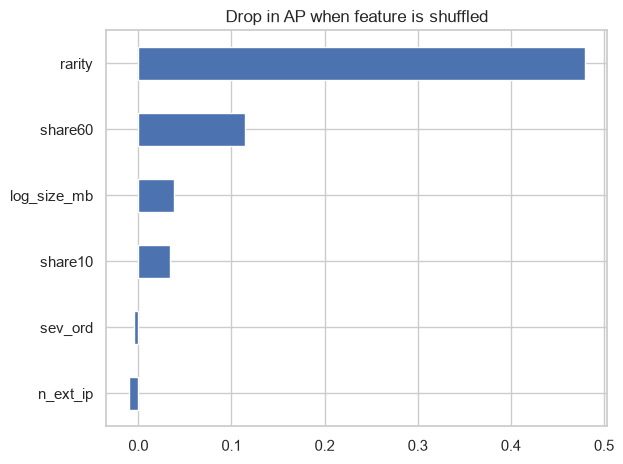

In [38]:
Xf = F_full[cols_c]
base = average_precision_score(y_true, det.score_features(Xf))
rng = np.random.default_rng(SEED)
imp = {}
for c in cols_c:
    drops = []
    for _ in range(5):
        Xp = Xf.copy(); Xp[c] = rng.permutation(Xp[c].values)
        drops.append(base - average_precision_score(y_true, det.score_features(Xp)))
    imp[c] = np.mean(drops)
pd.Series(imp).sort_values().plot.barh(title="Drop in AP when feature is shuffled"); plt.tight_layout(); plt.show()

## Part 7 - Streaming simulation and persistence
Micro-batches arrive in order; each is scored together with a small buffer of recent history (the longest window, 60 s) so that burst features are computed exactly as in batch mode. We verify the streamed scores equal the batch scores.

In [39]:
def stream_score(detector, df, batch_size=500, buffer_seconds=60):
    buf, out = df.iloc[0:0], []
    for start in range(0, len(df), batch_size):
        batch = df.iloc[start:start + batch_size]
        work = pd.concat([buf, batch])
        F = detector.fb.transform(work).iloc[len(buf):]
        out.append(detector.score_features(F))
        buf = work[work.timestamp >= work.timestamp.max() - pd.Timedelta(seconds=buffer_seconds)]
    return np.concatenate(out)


stream_input = test[["timestamp", "severity", "message"]]
streamed = stream_score(det, stream_input)
print("streamed == batch scores:", np.allclose(streamed, test.score.values))
print("alerts (stream):", int((streamed >= det.threshold).sum()), "| alerts (batch):", int(test.alert.sum()))

streamed == batch scores: True
alerts (stream): 153 | alerts (batch): 153


In [40]:
joblib.dump(det, ART_DIR / "isolation_forest_detector.joblib")
test.loc[test.alert == 1, ["event_id", "timestamp", "host", "severity", "message", "score", "attack"]] \
    .sort_values("score", ascending=False).to_csv(ART_DIR / "alerts.csv", index=False)
print("saved:", sorted(p.name for p in ART_DIR.iterdir()))
print("NOTE: to reload the detector, define FeatureBuilder / AnomalyDetector (and helpers) from this notebook first.")

saved: ['alerts.csv', 'isolation_forest_detector.joblib', 'message_detector.joblib']
NOTE: to reload the detector, define FeatureBuilder / AnomalyDetector (and helpers) from this notebook first.


## Conclusions

**Data**
* `train.csv` (159 rows, 30 distinct messages) has labels that are a deterministic, semantically arbitrary function of the message string and a 62% anomaly rate. It is unusable as supervised ground truth (group-CV shows no gain over a severity rule) and shares **zero** message templates with the test stream.
* `test.csv` is a 10k-event stream with ~99% routine traffic and a handful of attack patterns: exfiltration, port scans, WARNING-level SSH brute force, impossible-travel VPN logins and an off-hours root/admin login -> sudo -> DB dump chain.

**Model**
* Unsupervised **Isolation Forest** on message-derived features (template rarity, severity, magnitude, external IP, entity concentration) is clearly the best of the options tried: AP ~0.92 (0.93 +/- 0.02 over 10 seeds), ROC-AUC 0.999, ~98% recall at a 1.5% alert budget, versus AP 0.39 for a severity rule or `severity + message rarity` alone, 0.32 for One-Class SVM and 0.28 for LOF.
* Every proxy attack class is detected (100% recall), including the 98 WARNING-level brute-force events that a severity rule can never catch. Remaining false positives are mainly firewall DROPs and the benign VPN login that precedes an impossible-travel event.
* "Train on the past, score the future" (fit on the first half, fixed threshold): precision 0.95, recall 1.00 on the second half.
* The streaming simulation reproduces batch scores exactly with only a 60 s history buffer.

**What mattered most** (ablation): `severity` + message text alone is weak. Gains come from the *entity concentration* feature (what share of a template's recent events come from one IP/user). Raw rolling counts mostly measure traffic volume and hurt; text SVD gives a small, within-noise gain.

**Caveats / next steps**
* Metrics are against **proxy labels** I derived from `event_type` / `source_ip` / `bytes_out`, and the feature set was chosen while looking at them, so treat the numbers as optimistic. Get a small analyst-labelled sample to validate and to set the alert threshold.
* The stream covers only ~9 minutes of activity; verify on longer, drifting traffic and refit the detector periodically on a trailing window of recent normal traffic.
* Template / entity extraction is regex-based and tuned to these message formats. For new log sources use a log parser such as Drain3.
* Pick the alert budget (here 1.5%) from analyst capacity. For true online learning, consider River's HalfSpaceTrees on the same features.

## Part 8 - Combined training set (`train.csv` + a sample of `test.csv`)
`test.csv` rows are mapped to the `train.csv` schema (`type`, `line`, `anomaly_score`; -1 = anomaly, 1 = normal) using the proxy labels from Part 3. Every distinct anomalous line is kept and distinct normal lines are taken evenly across message templates. If that is fewer than `TARGET_ROWS`, the rest is filled with repeated normal events from the stream.

In [41]:
TARGET_ROWS = 7000

full = pd.DataFrame({"type": test.severity, "line": test.severity + " " + test.message,
                     "anomaly_score": np.where(test.y == 1, -1, 1), "tpl": test.tpl, "attack": test.attack})
is_repeat = full.duplicated("line")
stream = full[~is_repeat].sample(frac=1, random_state=SEED)

COLS = ["type", "line", "anomaly_score"]
train_unique = train[COLS].drop_duplicates()  # 119 of the 159 train rows are exact repeats

# Every distinct anomalous line is kept; normals fill the remaining budget round-robin across templates.
anom = stream[stream.anomaly_score == -1]
normal = stream[stream.anomaly_score == 1]
n_normal = TARGET_ROWS - len(train_unique) - len(anom)
normal = normal.assign(rank=normal.groupby("tpl").cumcount()).sort_values("rank", kind="stable").head(n_normal)

# Distinct normal lines run out below TARGET_ROWS; top up with real repeated normal events from the stream.
n_extra = max(0, n_normal - len(normal))
extra = full[is_repeat & (full.anomaly_score == 1)].sample(n_extra, random_state=SEED)
stream_sample = pd.concat([anom, normal, extra])

combined = (pd.concat([train_unique, stream_sample[COLS]], ignore_index=True)
            .sample(frac=1, random_state=SEED).reset_index(drop=True))
combined.to_csv(Path("data") / "combined_train.csv", index=False)

print(f"train rows: {len(train)} -> {len(train_unique)} unique | sampled from test: {len(stream_sample)} (of {len(test)}) | combined: {len(combined)}")
print(f"anomaly rate: train {(train_unique.anomaly_score == -1).mean():.1%} | test sample {(stream_sample.anomaly_score == -1).mean():.1%} | combined {(combined.anomaly_score == -1).mean():.1%}")
print(f"distinct normal lines: {len(normal)} | repeated normal lines added: {n_extra} | exact-duplicate rows in file: {combined.duplicated().sum()}")
display(pd.crosstab(combined.type, combined.anomaly_score))
display(stream_sample[stream_sample.anomaly_score == -1].attack.value_counts().to_frame("rows kept"))

train rows: 159 -> 40 unique | sampled from test: 6960 (of 10000) | combined: 7000
anomaly rate: train 57.5% | test sample 1.9% | combined 2.2%
distinct normal lines: 2046 | repeated normal lines added: 4780 | exact-duplicate rows in file: 4780


anomaly_score,-1,1
type,,
CRITICAL,2,0
ERROR,47,17
INFO,2,5724
WARNING,106,1102


,rows kept
attack,
ssh_brute_force,98
exfiltration,19
suspicious_login,8
port_scan,6
privilege_escalation,2
data_dump,1


## Part 9 - Tuning on `combined_train.csv`
The combined file only has `type` / `line` / `anomaly_score`, so there are no timestamps and the time-window features of Parts 4-7 are unavailable. This part builds a **message-level** detector instead (severity, template rarity, message magnitude, external IPs, text SVD). Rarity and the text vectoriser are fitted on the *unlabelled* stream, so no labels leak into the features.

Because the file contains repeated lines and its anomalies come from a handful of templates, plain K-fold would be badly optimistic. Two grouped cross-validation schemes are used instead, scored **only on the rows that came from `test.csv`**:
* **group = exact line** (known attack types, new IPs/users/sizes): the realistic production case.
* **group = message template** (completely unseen message types): the hard case.

The 40 `train.csv` rows are added to every training fold or left out, to measure whether they help.

In [42]:
SEV_RE = re.compile(r"^(INFO|WARNING|ERROR|CRITICAL)\s+")
BASE_COLS = ["sev_ord", "rarity", "log_size_mb", "n_ext_ip"]
ALL_COLS = BASE_COLS + [f"text_svd_{i}" for i in range(6)]


def strip_severity(line: pd.Series) -> pd.Series:
    return line.str.replace(SEV_RE, "", regex=True)


class MsgFeatures:
    """Stateless-per-row features from (type, line); reference statistics come from an unlabelled message set."""

    def __init__(self, svd_components=6, seed=SEED):
        self.svd_components, self.seed = svd_components, seed

    def fit(self, messages: pd.Series):
        tpl = messages.map(to_template)
        self.tpl_counts_, self.n_ref_ = tpl.value_counts().to_dict(), len(tpl)
        uniq = pd.Series(tpl.unique())
        self.tfidf_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit(uniq)
        self.svd_ = TruncatedSVD(self.svd_components, random_state=self.seed).fit(self.tfidf_.transform(uniq))
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        msg = strip_severity(df.line)
        tpl = msg.map(to_template)
        parsed = np.array([parse_message(m)[:2] for m in msg]).reshape(-1, 2)
        F = pd.DataFrame(index=df.index)
        F["sev_ord"] = df.type.map(SEV_MAP).fillna(0).values
        F["rarity"] = -np.log((tpl.map(self.tpl_counts_).fillna(0).values + 1) / (self.n_ref_ + 1))
        F["log_size_mb"], F["n_ext_ip"] = np.log1p(parsed[:, 0]), parsed[:, 1]
        svd = self.svd_.transform(self.tfidf_.transform(tpl))
        for i in range(svd.shape[1]):
            F[f"text_svd_{i}"] = svd[:, i]
        return F


combined = pd.read_csv(Path("data") / "combined_train.csv")
combined["tpl"] = strip_severity(combined.line).map(to_template)
combined["from_train_csv"] = combined.line.isin(set(train.line))
y = (combined.anomaly_score == -1).astype(int).values

features = MsgFeatures().fit(test.message)
X = features.transform(combined)

print(f"rows: {len(combined)} | anomalies: {y.sum()} ({y.mean():.1%}) | from train.csv: {combined.from_train_csv.sum()} | from test.csv: {(~combined.from_train_csv).sum()}")
print(f"distinct lines: {combined.line.nunique()} | distinct templates: {combined.tpl.nunique()}")
display(combined[y == 1].groupby("tpl").size().sort_values(ascending=False).to_frame("anomalous rows").head(12))

rows: 7000 | anomalies: 157 (2.2%) | from train.csv: 40 | from test.csv: 6960
distinct lines: 2220 | distinct templates: 92


,anomalous rows
tpl,
Failed password for <USER> from <IP> port <PORT> ssh2,98
Large outbound transfer of <N> MB to <IP>,19
VPN login for <USER> from <CC> two minutes after <CC>,6
Port scan detected from <IP>,6
Database connection failed,4
<USER> logged in from <IP> outside business hours,2
Unhandled exception in payment module,2
Service health check failed,2
Network latency detected,2


In [43]:
def fold_metrics(score, y_true):
    k = int(y_true.sum())
    top = np.zeros(len(y_true), dtype=int)
    top[np.argsort(-score)[:k]] = 1
    return {"AP": average_precision_score(y_true, score), "ROC_AUC": roc_auc_score(y_true, score), "F1@k": f1_score(y_true, top)}


def run_cv(models, groups, use_train_csv, n_splits=5, seed=SEED):
    """Grouped CV scored on test.csv rows only; train.csv rows (if used) are added to every training fold."""
    ev = np.flatnonzero(~combined.from_train_csv.values)
    extra = np.flatnonzero(combined.from_train_csv.values) if use_train_csv else np.array([], dtype=int)
    rows, oof = [], {name: np.full(len(combined), np.nan) for name in models}
    for k, (tr, te) in enumerate(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(ev, y[ev], groups[ev])):
        tr_idx, te_idx = np.concatenate([ev[tr], extra]), ev[te]
        for name, fn in models.items():
            s = fn(X.iloc[tr_idx], y[tr_idx], X.iloc[te_idx])
            oof[name][te_idx] = s
            if y[te_idx].any():
                rows.append({"model": name, "fold": k, **fold_metrics(s, y[te_idx])})
    return pd.DataFrame(rows), oof


def sev_rule(Xtr, ytr, Xte):
    return Xte.sev_ord.values.astype(float)


def iforest(Xtr, ytr, Xte):
    m = IsolationForest(n_estimators=300, max_samples=256, random_state=SEED, n_jobs=-1).fit(Xtr[BASE_COLS].values)
    return -m.score_samples(Xte[BASE_COLS].values)


def supervised(make, cols=ALL_COLS):
    def run(Xtr, ytr, Xte):
        return make().fit(Xtr[cols].values, ytr).predict_proba(Xte[cols].values)[:, 1]
    return run


MODELS = {
    "Rule: severity >= ERROR": sev_rule,
    "IsolationForest (unsupervised)": iforest,
    "LogReg (balanced)": supervised(lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))),
    "RandomForest (balanced)": supervised(lambda: RandomForestClassifier(300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    "HistGB (balanced)": supervised(lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)),
}
SCHEMES = {"line": combined.line.values, "template": combined.tpl.values}

results = []
for scheme, groups in SCHEMES.items():
    for use_csv in (True, False):
        r, _ = run_cv(MODELS, groups, use_csv)
        results.append(r.assign(scheme=scheme, train_csv_rows=use_csv))
res = pd.concat(results)
summary = res.groupby(["scheme", "train_csv_rows", "model"])[["AP", "ROC_AUC", "F1@k"]].mean().round(3)
display(summary)
print("folds with anomalies:", res.groupby(["scheme", "train_csv_rows"]).fold.nunique().to_dict())

AP  ROC_AUC   F1@k
scheme   train_csv_rows model                                                
line     False          HistGB (balanced)               1.000    1.000  1.000
                        IsolationForest (unsupervised)  0.765    0.993  0.513
                        LogReg (balanced)               0.999    1.000  0.993
                        RandomForest (balanced)         1.000    1.000  1.000
                        Rule: severity >= ERROR         0.348    0.941  0.351
         True           HistGB (balanced)               1.000    1.000  1.000
                        IsolationForest (unsupervised)  0.841    0.996  0.714
                        LogReg (balanced)               0.976    1.000  0.970
                        RandomForest (balanced)         1.000    1.000  1.000
                        Rule: severity >= ERROR         0.348    0.941  0.351
template False          HistGB (balanced)               0.619    0.795  0.604
                        IsolationForest (unsupervised)  0.963    0.997  0.955
                        LogReg (balanced)               1.000    1.000  1.000
                        RandomForest (balanced)         1.000    1.000  1.000
                        Rule: severity >= ERROR         0.866    0.985  0.861
         True           HistGB (balanced)               0.805    0.896  0.800
                        IsolationForest (unsupervised)  0.963    0.997  0.955
                        LogReg (balanced)               0.988    0.999  0.988
                        RandomForest (balanced)         1.000    1.000  1.000
                        Rule: severity >= ERROR         0.866    0.985  0.861

folds with anomalies: {('line', False): 5, ('line', True): 5, ('template', False): 5, ('template', True): 5}


**Reading the comparison**
* Supervised models (RandomForest, LogReg, HistGB) reach AP close to 1.0 on unseen lines, far above the Isolation Forest without time features (about 0.77-0.84) and the severity rule (0.35). With the 7,000-row file the labelled data is now enough for supervised learning.
* Scores this high mostly show that the **proxy labels are a near-deterministic function of what the message exposes** (external IP, severity, "Large outbound transfer", "Port scan"...), because the labels were derived from `event_type` / `source_ip` / `bytes_out`. They are not evidence of the same accuracy against real attacks.
* RandomForest and LogReg also hold up when whole templates are held out; HistGB does not (AP 0.62-0.81), so it is the least robust.
* Adding the 40 `train.csv` rows never improves the best models and hurts LogReg, consistent with their arbitrary labels. They are excluded from the final model unless they win clearly.

In [44]:
from itertools import product

RF_NAME = "RandomForest (balanced)"
rf_ap = res[res.model == RF_NAME].groupby("train_csv_rows").AP.mean()
USE_TRAIN_CSV = bool(rf_ap[True] > rf_ap[False])  # only if the arbitrary train.csv labels clearly help
print("use train.csv rows:", USE_TRAIN_CSV)


def make_rf(**p):
    return lambda: RandomForestClassifier(300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED, **p)


tuned = []
for depth, leaf, mf in product([None, 8], [1, 2, 5], ["sqrt", 0.5]):
    p = {"max_depth": depth, "min_samples_leaf": leaf, "max_features": mf}
    per_scheme = {s: run_cv({"rf": supervised(make_rf(**p))}, g, USE_TRAIN_CSV)[0][["AP", "F1@k"]].mean() for s, g in SCHEMES.items()}
    tuned.append({"params": p, "AP_line": per_scheme["line"].AP, "AP_template": per_scheme["template"].AP,
                  "F1_line": per_scheme["line"]["F1@k"], "F1_template": per_scheme["template"]["F1@k"]})

tuned_df = pd.DataFrame(tuned)
tuned_df["AP_mean"] = tuned_df[["AP_line", "AP_template"]].mean(axis=1)
tuned_df["F1_mean"] = tuned_df[["F1_line", "F1_template"]].mean(axis=1)
tuned_df["leaf"] = [t["params"]["min_samples_leaf"] for t in tuned]
tuned_df["depth"] = [t["params"]["max_depth"] or 99 for t in tuned]
# Scores are saturated, so ties go to the more regularised model (larger leaves, shallower trees).
order = tuned_df.sort_values(["AP_mean", "F1_mean", "leaf", "depth"], ascending=[False, False, False, True]).index
best_params = tuned[order[0]]["params"]
display(pd.concat([pd.DataFrame([t["params"] for t in tuned]).astype(str), tuned_df.drop(columns=["params", "leaf", "depth"]).round(3)], axis=1).loc[order])
print("selected:", best_params)

# Which feature groups does the model depend on? (CV with each group removed)
groups_to_drop = {"none (all features)": [], "sev_ord": ["sev_ord"], "rarity": ["rarity"], "log_size_mb": ["log_size_mb"],
                  "n_ext_ip": ["n_ext_ip"], "text_svd_*": [c for c in ALL_COLS if c.startswith("text_svd")]}
abl = []
for name, drop in groups_to_drop.items():
    cols = [c for c in ALL_COLS if c not in drop]
    row = {"dropped": name}
    for s, g in SCHEMES.items():
        r, _ = run_cv({"rf": supervised(make_rf(**best_params), cols)}, g, USE_TRAIN_CSV)
        row[f"AP_{s}"] = r.AP.mean()
    abl.append(row)
display(pd.DataFrame(abl).round(3))

use train.csv rows: False


,max_depth,min_samples_leaf,max_features,AP_line,AP_template,F1_line,F1_template,AP_mean,F1_mean
10,8.0,5,sqrt,1.0,1.0,1.0,1.0,1.0,1.0
11,8.0,5,0.5,1.0,1.0,1.0,1.0,1.0,1.0
4,NaN,5,sqrt,1.0,1.0,1.0,1.0,1.0,1.0
5,NaN,5,0.5,1.0,1.0,1.0,1.0,1.0,1.0
8,8.0,2,sqrt,1.0,1.0,1.0,1.0,1.0,1.0
9,8.0,2,0.5,1.0,1.0,1.0,1.0,1.0,1.0
2,NaN,2,sqrt,1.0,1.0,1.0,1.0,1.0,1.0
3,NaN,2,0.5,1.0,1.0,1.0,1.0,1.0,1.0
6,8.0,1,sqrt,1.0,1.0,1.0,1.0,1.0,1.0
7,8.0,1,0.5,1.0,1.0,1.0,1.0,1.0,1.0


selected: {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt'}


,dropped,AP_line,AP_template
0,none (all features),1.000,1.000
1,sev_ord,0.999,0.805
2,rarity,0.996,1.000
3,log_size_mb,0.996,1.000
4,n_ext_ip,0.542,0.871
5,text_svd_*,1.000,0.866


**Tuning result:** the grid is flat (every setting reaches AP and F1 of about 1.0 in both CV schemes), so hyper-parameters are not the lever here. The more regularised setting is chosen on ties. The ablation shows the model leans heavily on `n_ext_ip` (AP drops to 0.54 on unseen lines without it), which mirrors how the proxy labels were built. `sev_ord` and the text SVD matter when a whole template is unseen.

In [45]:
class MessageDetector:
    def __init__(self, features, model, threshold):
        self.features, self.model, self.threshold = features, model, threshold

    def score(self, df):
        """`df` needs `type` (severity) and `line` ("SEVERITY message")."""
        return self.model.predict_proba(self.features.transform(df)[ALL_COLS].values)[:, 1]

    def predict(self, df):
        return (self.score(df) >= self.threshold).astype(int)


rf_factory = supervised(make_rf(**best_params))
oof_by_scheme = {s: run_cv({"rf": rf_factory}, g, USE_TRAIN_CSV)[1]["rf"] for s, g in SCHEMES.items()}

# Alert threshold: best F1 on the out-of-fold probabilities for unseen lines.
p_line = oof_by_scheme["line"]
seen = ~np.isnan(p_line)
prec, rec, thr = precision_recall_curve(y[seen], p_line[seen])
f1_curve = 2 * prec * rec / (prec + rec + 1e-12)
threshold = float(thr[f1_curve[:-1].argmax()])

report = {}
for s, p in oof_by_scheme.items():
    m = ~np.isnan(p)
    pred = (p[m] >= threshold).astype(int)
    report[s] = {"precision": precision_score(y[m], pred), "recall": recall_score(y[m], pred), "F1": f1_score(y[m], pred),
                 "alerts": int(pred.sum()), "anomalies": int(y[m].sum())}
print(f"threshold={threshold:.3f}")
display(pd.DataFrame(report).T.round(3))

train_idx = np.flatnonzero(~combined.from_train_csv.values | USE_TRAIN_CSV)
final_model = make_rf(**best_params)().fit(X.iloc[train_idx][ALL_COLS].values, y[train_idx])
detector = MessageDetector(features, final_model, threshold)
joblib.dump(detector, ART_DIR / "message_detector.joblib")

# Errors on unseen lines, to see what the model still gets wrong.
oof_pred = (p_line >= threshold).astype(int)
errors = combined[seen & (oof_pred != y)].assign(oof_prob=p_line[seen & (oof_pred != y)].round(3))
print(f"misclassified on unseen lines: {len(errors)} of {seen.sum()}")
display(errors[["line", "anomaly_score", "oof_prob"]].drop_duplicates("line").head(10))

demo = pd.DataFrame({"type": ["WARNING", "WARNING", "ERROR", "INFO"],
                     "line": ["WARNING Failed password for admin from 203.0.113.7 port 51234 ssh2",
                              "WARNING Failed password for alice from 10.0.1.15 port 40222 ssh2",
                              "ERROR Large outbound transfer of 950 MB to 198.51.100.4",
                              "INFO GET /health HTTP/1.1 200"]})
display(demo.assign(prob=detector.score(demo).round(3), alert=detector.predict(demo)))

threshold=0.256


,precision,recall,F1,alerts,anomalies
line,1.000,1.000,1.000,134.0,134.0
template,0.048,0.269,0.082,747.0,134.0


misclassified on unseen lines: 0 of 6960


,line,anomaly_score,oof_prob


,type,line,prob,alert
0,WARNING,WARNING Failed password for admin from 203.0.113.7 port 51234 ssh2,0.998,1
1,WARNING,WARNING Failed password for alice from 10.0.1.15 port 40222 ssh2,0.174,0
2,ERROR,ERROR Large outbound transfer of 950 MB to 198.51.100.4,1.000,1
3,INFO,INFO GET /health HTTP/1.1 200,0.103,0


### Part 9 conclusions
* **Model:** RandomForest (`max_depth=8`, `min_samples_leaf=5`, `max_features="sqrt"`, balanced class weights) on message-level features, trained on the 6,960 `test.csv` rows of `combined_train.csv`. The 40 `train.csv` rows are left out. Saved to `artifacts/message_detector.joblib`.
* **Known attack types, new IPs/users/sizes:** 0 errors out of 6,960 out-of-fold rows (precision, recall and F1 all 1.0 at threshold 0.256), versus AP of about 0.77-0.84 for the Isolation Forest without time features.
* **Completely unseen message templates:** ranking still works (per-fold AP about 1.0), but the fixed threshold does not transfer (precision 0.05, recall 0.27 pooled). For new log sources, alert on the top-k scores or fall back to the unsupervised detector of Parts 4-7, which needs no labels.
* **Caveat:** these labels are proxy labels derived from `event_type` / `source_ip` / `bytes_out`, so near-perfect scores show the model recovered that rule (mostly through external-IP counts). Confirm with analyst-labelled events before trusting the numbers.
* **Streaming:** the message-level model cannot see bursts. Keep the Part 6-7 detector (entity share, time windows) alongside it; a simple combination is to alert when either score fires.

## Part 10 - Compare on the full test stream and export results
Every distinct line of `test.csv` is in `combined_train.csv`, so scoring the stream with the final message model is partly in-sample. The honest comparison uses the **out-of-fold** probability of each line (the model that never saw that line). It is compared with the severity rule, the unsupervised stream Isolation Forest (Parts 4-7) and a hybrid that alerts when either detector fires.

Saved files: `artifacts/message_detector.joblib` and `artifacts/isolation_forest_detector.joblib` (scikit-learn models, so joblib; the `.ubj` format only exists for XGBoost), `artifacts/test_scored_results.csv` (per-event scores and alerts) and `artifacts/model_results.json` (metrics, parameters, threshold).

In [46]:
test["line"] = test.severity + " " + test.message
oof_line = pd.Series(oof_by_scheme["line"], index=combined.line).dropna().groupby(level=0).mean()
test["p_msg_oof"] = test.line.map(oof_line)
print("test rows without an out-of-fold score:", int(test.p_msg_oof.isna().sum()))
test["p_msg_final"] = detector.score(test.rename(columns={"severity": "type"})[["type", "line"]])

test["alert_msg_oof"] = (test.p_msg_oof >= detector.threshold).astype(int)
test["alert_msg_final"] = (test.p_msg_final >= detector.threshold).astype(int)
test["alert_hybrid"] = ((test.alert_msg_oof == 1) | (test.alert == 1)).astype(int)
test["score_hybrid"] = np.maximum(test.p_msg_oof.rank(pct=True), test.score.rank(pct=True))
test["alert_rule"] = (test.severity.isin(["ERROR", "CRITICAL"])).astype(int)

COMPARE = {
    "Severity rule (>= ERROR)": (F_full.sev_ord.values.astype(float), "alert_rule"),
    "Stream Isolation Forest (Parts 4-7, unsupervised)": (test.score.values, "alert"),
    "Message RF, out-of-fold (honest)": (test.p_msg_oof.values, "alert_msg_oof"),
    "Message RF, final model (in-sample)": (test.p_msg_final.values, "alert_msg_final"),
    "Hybrid: RF out-of-fold OR stream IF": (test.score_hybrid.values, "alert_hybrid"),
}
rows = {}
for name, (score, alert_col) in COMPARE.items():
    a = test[alert_col].values
    rows[name] = {"ROC_AUC": roc_auc_score(y_true, score), "AP": average_precision_score(y_true, score),
                  "alerts": int(a.sum()), "TP": int(((a == 1) & (y_true == 1)).sum()), "FP": int(((a == 1) & (y_true == 0)).sum()),
                  "precision": precision_score(y_true, a), "recall": recall_score(y_true, a), "F1": f1_score(y_true, a)}
comparison = pd.DataFrame(rows).T
display(comparison.round(3))

per_attack_recall = pd.DataFrame({name: test[test.y == 1].groupby("attack")[col].mean() for name, (_, col) in COMPARE.items()})
display(per_attack_recall.round(3))

test rows without an out-of-fold score: 0


,ROC_AUC,AP,alerts,TP,FP,precision,recall,F1
Severity rule (>= ERROR),0.955,0.346,37.0,37.0,0.0,1.000,0.274,0.430
"Stream Isolation Forest (Parts 4-7, unsupervised)",0.999,0.916,153.0,135.0,18.0,0.882,1.000,0.938
"Message RF, out-of-fold (honest)",1.000,1.000,135.0,135.0,0.0,1.000,1.000,1.000
"Message RF, final model (in-sample)",1.000,1.000,135.0,135.0,0.0,1.000,1.000,1.000
Hybrid: RF out-of-fold OR stream IF,1.000,0.958,153.0,135.0,18.0,0.882,1.000,0.938


,Severity rule (>= ERROR),"Stream Isolation Forest (Parts 4-7, unsupervised)","Message RF, out-of-fold (honest)","Message RF, final model (in-sample)",Hybrid: RF out-of-fold OR stream IF
attack,,,,,
data_dump,1.0,1.0,1.0,1.0,1.0
exfiltration,1.0,1.0,1.0,1.0,1.0
port_scan,1.0,1.0,1.0,1.0,1.0
privilege_escalation,1.0,1.0,1.0,1.0,1.0
ssh_brute_force,0.0,1.0,1.0,1.0,1.0
suspicious_login,1.0,1.0,1.0,1.0,1.0


In [47]:
export_cols = ["event_id", "timestamp", "host", "severity", "message", "attack", "y", "score", "alert",
               "p_msg_oof", "alert_msg_oof", "p_msg_final", "alert_msg_final", "alert_hybrid"]
test[export_cols].rename(columns={"y": "proxy_label", "score": "stream_if_score", "alert": "alert_stream_if"}) \
    .to_csv(ART_DIR / "test_scored_results.csv", index=False)

cv_summary = res.groupby(["scheme", "train_csv_rows", "model"])[["AP", "ROC_AUC", "F1@k"]].mean().round(4)
model_results = {
    "training_data": {"file": "data/combined_train.csv", "rows": int(len(combined)), "anomalies": int(y.sum()),
                      "train_csv_rows_used": bool(USE_TRAIN_CSV)},
    "message_model": {"type": "RandomForestClassifier", "params": {k: v for k, v in best_params.items()}, "alert_threshold": threshold,
                      "features": ALL_COLS, "file": "artifacts/message_detector.joblib"},
    "cv_unseen_lines_and_templates": report,
    "cv_model_comparison": {"/".join(map(str, k)): v for k, v in cv_summary.to_dict("index").items()},
    "test_stream_comparison": comparison.round(4).to_dict("index"),
    "test_stream_per_attack_recall": per_attack_recall.round(4).to_dict("index"),
    "note": "Labels are proxy labels derived from event_type/source_ip/bytes_out; treat scores as optimistic.",
}
(ART_DIR / "model_results.json").write_text(json.dumps(model_results, indent=2, default=float), encoding="utf-8")
print("saved:", sorted(p.name for p in ART_DIR.iterdir()))

saved: ['alerts.csv', 'isolation_forest_detector.joblib', 'message_detector.joblib', 'model_results.json', 'test_scored_results.csv']
